## 🎯 Project: Employee Salary Prediction


# Steps

 0. Preprocess + EDA + Feature Selection
 1. Extract input and output cols
 2. Scale the values
 3. Train test split
 4. Train the model
 5. Evaluate the model/model selection
 6. Deploy the model
     

In [406]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [407]:
df = pd.read_csv('Salary_Data.csv')

## **Understanding the data**

In [408]:
df.sample(7)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
4618,34.0,Male,Master's Degree,Web Developer,8.0,90000.0
1814,42.0,Male,PhD,Software Engineer Manager,14.0,190000.0
1701,27.0,Male,Bachelor's Degree,Back end Developer,3.0,85000.0
6578,45.0,Male,Master's Degree,Marketing Manager,13.0,130000.0
429,33.0,Male,PhD,Data Scientist,8.0,190000.0
3252,36.0,Male,PhD,Senior Data Scientist,12.0,170000.0
133,47.0,Male,PhD,Senior Research Scientist,22.0,160000.0


In [409]:
df.shape

(6704, 6)

In [410]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [411]:
df.isnull().mean()*100

Age                    0.029833
Gender                 0.029833
Education Level        0.044749
Job Title              0.029833
Years of Experience    0.044749
Salary                 0.074582
dtype: float64

In [412]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [413]:
df['Education Level'].value_counts()    

Education Level
Bachelor's Degree    2267
Master's Degree      1573
PhD                  1368
Bachelor's            756
High School           448
Master's              288
phD                     1
Name: count, dtype: int64

In [414]:
df['Education Level'] = df['Education Level'].replace({
    "Bachelor's Degree": "Bachelor's",
    "Master's Degree": "Master's",
    "phD": "PhD"
})

In [415]:
df['Education Level'].value_counts()  

Education Level
Bachelor's     3023
Master's       1861
PhD            1369
High School     448
Name: count, dtype: int64

In [416]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate columns:", df.columns.duplicated().sum())

Duplicate rows: 4913
Duplicate columns: 0


In [417]:
df = df.drop_duplicates()

In [418]:
df.shape

(1791, 6)

In [419]:
df.isnull().mean()*100

Age                    0.055835
Gender                 0.055835
Education Level        0.111669
Job Title              0.055835
Years of Experience    0.111669
Salary                 0.223339
dtype: float64

In [420]:
df.dtypes

Age                    float64
Gender                  object
Education Level         object
Job Title               object
Years of Experience    float64
Salary                 float64
dtype: object

 ## **EDA**

## Numerical

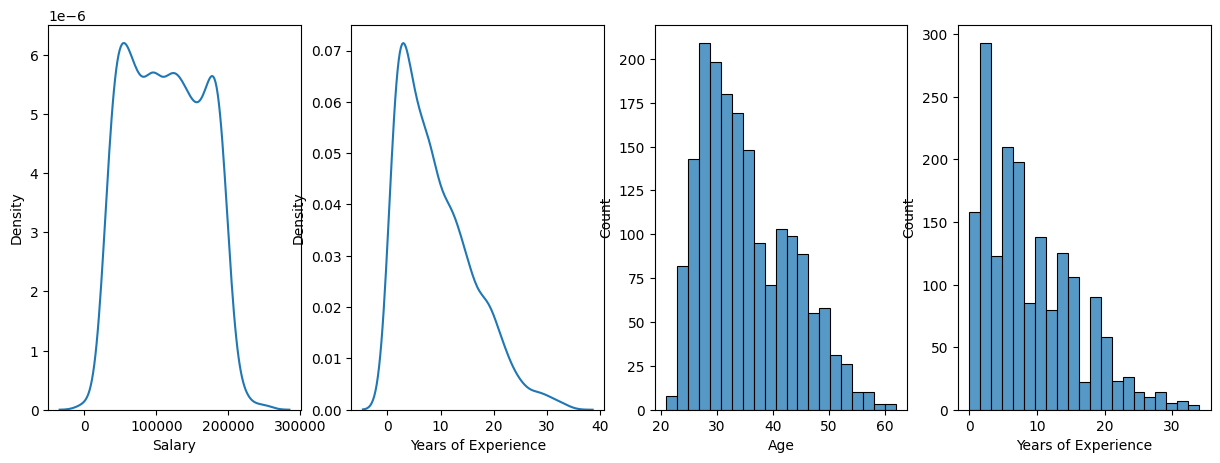

In [421]:
fig = plt.figure(figsize=(15,5))

plt.subplot(141)
sns.kdeplot(df['Salary'])

plt.subplot(142)
sns.kdeplot(df['Years of Experience'])



plt.subplot(143)
sns.histplot(df['Age'])

plt.subplot(144)
sns.histplot(df['Years of Experience'])

plt.show()

## Categorical

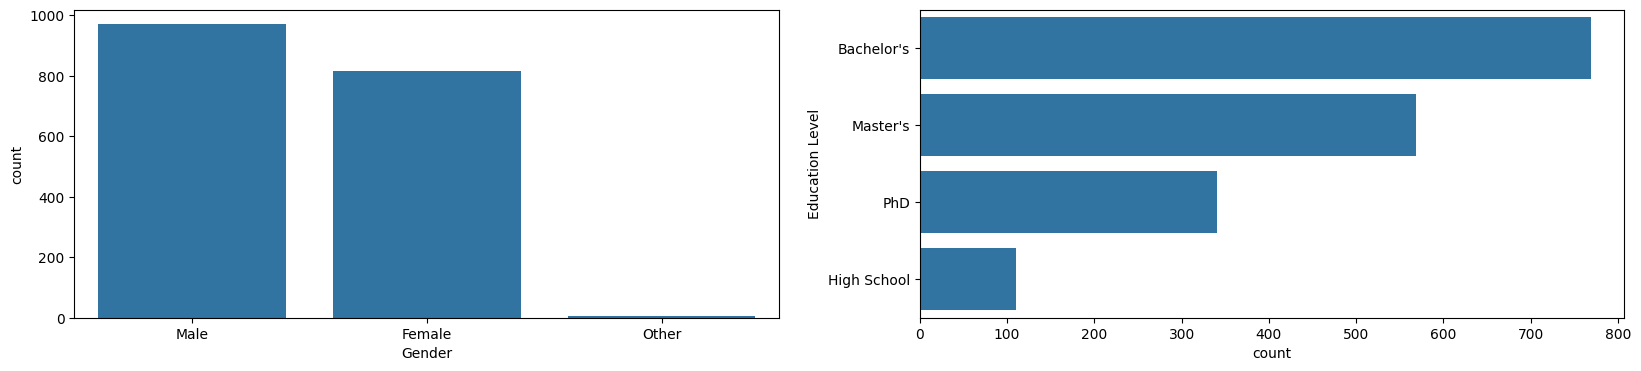

In [422]:
fig = plt.figure(figsize=(20,4))

#plt.subplot(121)
#sns.countplot(df['Job Title'])

plt.subplot(121)
sns.countplot(x = df['Gender'])

plt.subplot(122)
sns.countplot(y = df['Education Level'])

plt.show()
       

<Axes: xlabel='Gender', ylabel='Salary'>

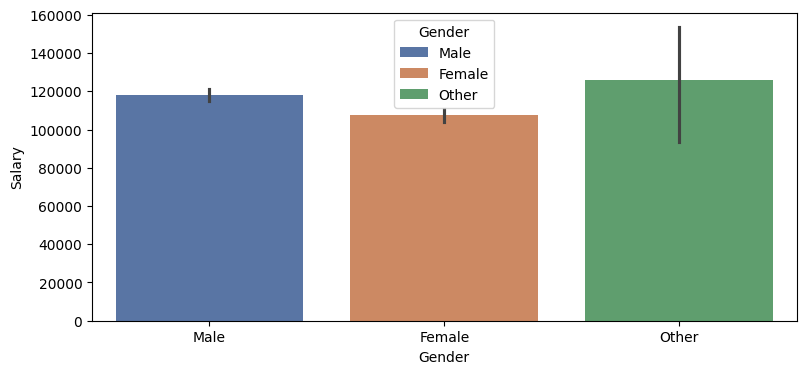

In [423]:
fig = plt.figure(figsize=(20,4))

plt.subplot(121)
sns.barplot(x=df['Gender'], y=df['Salary'], hue=df['Gender'], palette='deep')

<Axes: xlabel='Education Level', ylabel='Salary'>

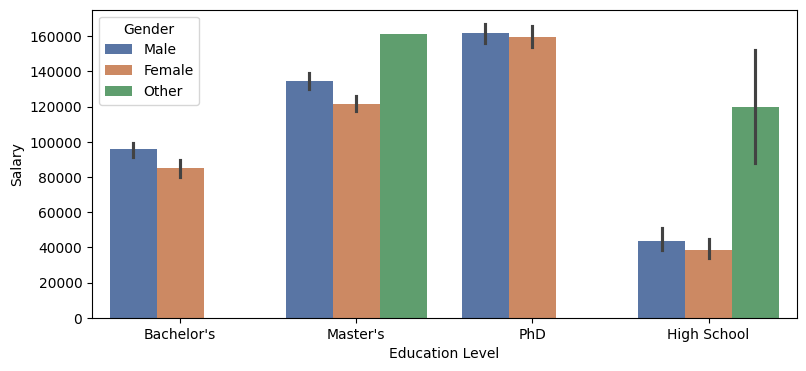

In [424]:
fig = plt.figure(figsize=(20,4))

plt.subplot(121)
sns.barplot(x=df['Education Level'], y=df['Salary'], hue=df['Gender'], palette='deep')

/var/folders/2s/95wdsz_j2jn5xl0d74jbk2fw0000gn/T/ipykernel_4573/3452630924.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=df['Job Title'].head(10), x=df['Salary'].head(10), palette='deep')


<Axes: xlabel='Salary', ylabel='Job Title'>

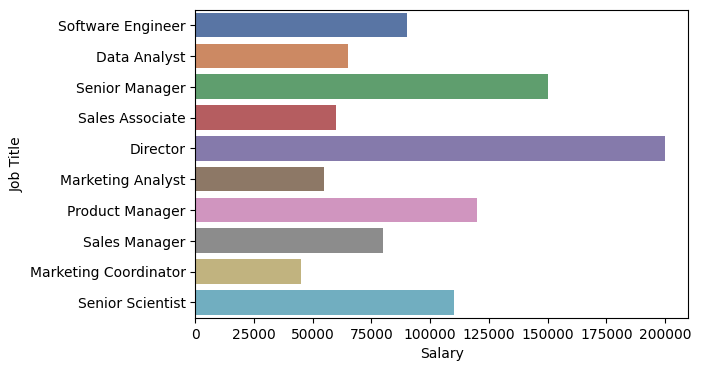

In [425]:
fig = plt.figure(figsize=(14,4))

plt.subplot(121)
sns.barplot(y=df['Job Title'].head(10), x=df['Salary'].head(10), palette='deep')

In [426]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


<Axes: xlabel='Years of Experience'>

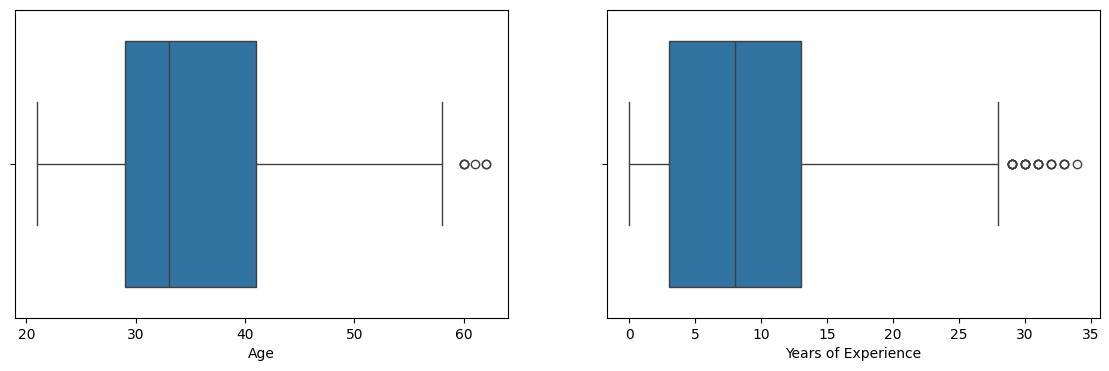

In [427]:
fig = plt.figure(figsize=(14,4))

plt.subplot(121)
sns.boxplot(x = df['Age'])

plt.subplot(122)
sns.boxplot(x = df['Years of Experience'])

## **Train Test Split**

In [428]:
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from sklearn.pipeline import Pipeline, make_pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [429]:
x = df.drop(columns=['Salary'])
y = df['Salary']

In [430]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [456]:
trf1 = ColumnTransformer([
    ('imputer1',SimpleImputer(strategy='mean'), ['Age', 'Years of Experience']),
], remainder='passthrough')

In [458]:
trf2 = ColumnTransformer([
    ('imputer2', SimpleImputer(strategy='most_frequent'), ['Gender', 'Education Level', 'Job Title']),
    ('ohe', OneHotEncoder(), ['Gender', 'Job Title']),
    ('oe', OrdinalEncoder(categories=[['High School', "Bachelor's", "Master's", 'PhD']]), ['Education Level'])
])

In [459]:
trf3 = DecisionTreeRegressor()

In [460]:
trf4 = LinearRegression()

In [461]:
trf5 = RandomForestRegressor(n_estimators=100, random_state=42)

## Creating Pipelines

In [462]:
pipe1 = make_pipeline(trf1, trf2, trf3)

In [463]:
pipe2 = make_pipeline(trf1, trf2, trf4)

In [464]:
pipe3 = make_pipeline(trf1, trf2, trf5)

In [465]:
print(type(x_train))
print(type(x_test))
print(type(y_train))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


In [466]:
pipe1.fit(x_train, y_train)

ValueError: Specifying the columns using strings is only supported for dataframes.

In [454]:
pipe1.fit(x_train, y_train)

ValueError: Specifying the columns using strings is only supported for dataframes.

In [455]:
pipe3.fit(x_train, y_train)

ValueError: Specifying the columns using strings is only supported for dataframes.